# Frequency, severity and pure premium models

This notebook builds the M3 models on `mart_person_year` and explains each step for a reviewer. Several
candidate model structures predict the same quantity, the expected annual PMI-scope cost of a person-year at
2023 prices. They are compared on one yardstick before one is chosen. The notebook uses aggregated tables
only and shows no person-level rows.

**Source.** AHRQ, Medical Expenditure Panel Survey (MEPS), Household Component, full-year consolidated files
HC-243 (2022) and HC-251 (2023), with the inpatient, outpatient and office-based event files.

## Data and metrics

**Which rows.** Models are fitted on the 2022 `train` rows, and scored on the 2022 `test` rows. The test rows
are a household-grouped sample of 2022, so no household is on both sides. The 2023 rows are held back for
the out-of-time test in M5 and are not loaded here.

**What is predicted.** One row is one person-year. A prediction is the expected annual cost of that
person-year, with its exposure included, so a part-year person has a smaller expected cost. Costs are at 2023
prices. Models are fitted unweighted, because an insurer would fit on its own book.

**Factors.** The 18 rating factor candidates are typed as categories. The reference level of each is the level
with the most train exposure, and it can never be `not_applicable` or `unknown`. Age is shown in single years
here. Banding comes in the level grouping task.

**Metrics.** Every candidate is scored by the same package code.

- **Tweedie deviance** on annual cost, with power 1.5. The ranking is re-checked at 1.3 and 1.7.
- **Gini**, weighted by exposure, for how well the predictions rank the person-years.
- **Lift and double-lift** tables, which compare actual with expected cost by group.
- **A/E** (actual divided by expected) overall, by factor level and by predicted-cost decile. A decile is a
  tenth of the exposure, ordered by predicted cost per exposure year, so a part-year person is placed by their
  annual rate.

In [1]:
import pandas as pd

from health_pricing.models import frame, metrics

pd.options.display.float_format = "{:,.3f}".format
frames = frame.load_frames()
frame.frame_summary(frames)

,split,person_years,exposure,claimants,claimant_rate,zero_cost_claimants,claims,cost,mean_cost_per_claimant
0,train,17596,"17,440.750",7229,0.411,34,53322,"38,080,040.270","5,267.677"
1,test,4151,"4,100.333",1731,0.417,6,12463,"9,748,983.247","5,631.995"


About 41 to 42 percent of person-years have at least one PMI-scope claim in both splits. Mean cost per claimant is
higher in test than in train, which is the first sign of how much a skewed cost varies between samples.
A few claimants have a claim of zero cost, counted in the `zero_cost_claimants` column. They count as claimants, and the severity
models will need to treat them explicitly.

### Reference levels

Age has the most exposure at 85 only because single years are not yet banded, so its reference level is
temporary. The reference levels of the other factors are the largest groups, as intended.

In [2]:
frame.reference_table(frames)

,factor,reference_level,exposure_share
0,age,85,0.022
1,region,3,0.384
2,inscov,1,0.592
3,rthlth,2,0.325
4,mnhlth,2,0.311
5,OFTSMK53,3,0.702
6,PHYEXE53,1,0.400
7,HIBPDX,0,0.500
8,CHDDX,0,0.756
9,ANGIDX,0,0.787


### Baseline

The baseline predicts the same cost per exposure year for everyone, the train mean. Every candidate has to beat
it. Its Gini is 0 by construction, because it does not rank anyone, and its A/E on train is 1.

In [3]:
metrics.baseline_scores(frames.train, frames.test)

,split,tweedie_deviance,mean_tweedie_deviance,gini,a_e
0,train,"3,694,004.075",209.934,0.000,1.000
1,test,"928,363.961",223.648,0.000,1.089


In [4]:
baseline = metrics.baseline_predictions(frames.train, frames.test)
pd.DataFrame(metrics.deviance_by_power(frames.test["cost"], baseline), index=["Test deviance"])

,1.300,1.500,1.700
Test deviance,"4,118,785.057","928,363.961","252,758.818"


The baseline's test A/E is above 1, so test cost per exposure year is higher than train. Part of this is
sampling variation in a skewed cost. Every candidate's test A/E should be read against this starting gap.
Deviances at different powers are on different scales, so they are only compared between candidates at the
same power. The power check asks whether the ranking of candidates changes.

## Benefit types

The stacked candidate (c) models the two benefit types separately. `mart_person_year_benefit` has two rows for
every person-year, with zeros where there is nothing to count. Event counts and costs add up to the claim
columns of the main modelling table.

- **Inpatient and day-case.** Every in-scope inpatient stay, and every in-scope outpatient or office-based visit
  where a surgical procedure was performed on the visit (`SURGPROC` = 1).
- **Outpatient.** All other in-scope visits. Visits where the procedure flag is inapplicable, refused or
  unknown are counted here.

The tables use 2023 prices and cover the modelling population.

In [5]:
from health_pricing import eda
from health_pricing.models import benefit

con = eda.connect()
benefit.benefit_summary(con)

,year,benefit_type,person_years,claimants,events,cost_2023_prices,events_share,cost_2023_prices_share
0,2022,inpatient_daycase,21747,"2,464.000","4,863.000","22,715,964.261",0.074,0.475
1,2022,outpatient,21747,"8,468.000","60,922.000","25,113,059.256",0.926,0.525
2,2023,inpatient_daycase,18463,"2,228.000","4,548.000","25,137,095.400",0.074,0.538
3,2023,outpatient,18463,"7,381.000","56,633.000","21,567,598.100",0.926,0.462


### What the procedure flag moves

This table covers every in-scope event in the event files, including people outside the modelling population,
at the prices of each survey year. The `all in-scope events` rows include the inpatient stays, which are never
moved. The flag moves a small share of events but a large share of cost, mainly in hospital outpatient visits.
The flag is a yes or no for the whole visit, so a minor procedure in a doctor's office counts as day-case.

In [6]:
shift = benefit.surgproc_shift(con)
con.close()
shift

,year,event_type,events,moved_events,cost,moved_cost,moved_events_share,moved_cost_share
0,2022,office_based,52602,2692,"19,541,406.280","2,808,890.470",0.051,0.144
1,2022,outpatient,13084,1506,"14,573,992.140","6,525,104.460",0.115,0.448
2,2022,all in-scope events,66406,4198,"47,120,394.730","9,333,994.930",0.063,0.198
3,2023,office_based,49654,2388,"17,166,857.780","2,122,309.290",0.048,0.124
4,2023,outpatient,11378,1459,"13,087,546.120","6,369,904.530",0.128,0.487
5,2023,all in-scope events,61792,3847,"47,159,982.900","8,492,213.820",0.062,0.180


## Leakage check on the unknown level

Adults who were never asked a question have the level `unknown`. For example, people who left the survey before
round 5/3, or who died before the priority-conditions section, are not asked the smoking, exercise or condition
questions. If `unknown` is really a marker for leaving or dying, it would predict cost for the wrong reason and
could not be used when pricing a policy. This section tests that on the 13 candidate factors that have an
`unknown` level. It uses adults in the 2022 train split only.

For each variable, adults at `unknown` are compared with adults who gave an answer. People who refused or did not
know are in neither group.

In [7]:
import matplotlib.pyplot as plt

from health_pricing.models import leakage

adults = leakage.load_leakage_frame()
comparison = leakage.unknown_level_table(adults)
comparison

,variable,group,person_years,mean_age,share_under_25,share_left_survey_early,share_exposure_under_1,mean_exposure,claimant_rate,mean_cost_per_claimant,cost_per_exposure_year
0,OFTSMK53,unknown,186,71.430,0.027,0.747,0.892,0.509,0.398,"27,712.301","21,643.380"
1,OFTSMK53,answered,13895,51.746,0.082,0.000,0.001,1.000,0.468,"5,293.445","2,476.125"
2,PHYEXE53,unknown,186,71.430,0.027,0.747,0.892,0.509,0.398,"27,712.301","21,643.380"
3,PHYEXE53,answered,13859,51.753,0.082,0.000,0.001,1.000,0.469,"5,290.742","2,479.764"
4,HIBPDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
5,HIBPDX,answered,14080,52.146,0.077,0.008,0.011,0.994,0.467,"5,556.539","2,608.726"
6,CHDDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
7,CHDDX,answered,14083,52.145,0.077,0.008,0.011,0.994,0.467,"5,550.613","2,604.990"
8,ANGIDX,unknown,113,29.062,0.805,0.177,0.212,0.829,0.230,"1,730.804",480.437
9,ANGIDX,answered,14084,52.143,0.077,0.008,0.011,0.994,0.467,"5,551.442","2,604.796"


The smoking and exercise questions have the same 186 adults at `unknown`. The nine adult-only condition flags have the
same 113, and the two flags asked at any age have the same 24. So the 13 rows above are only three different
groups of people.

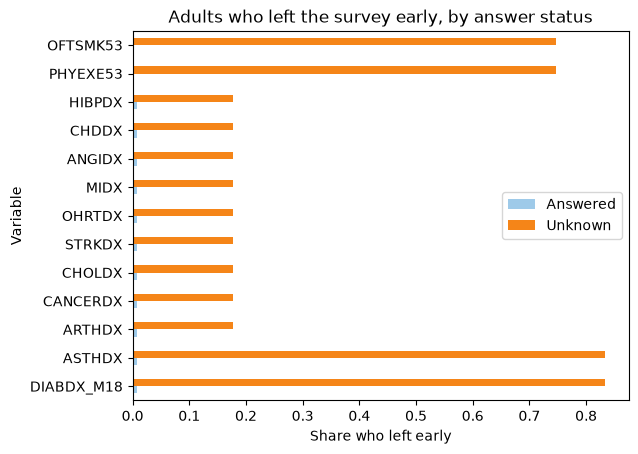

In [8]:
wide = comparison.pivot(index="variable", columns="group", values="share_left_survey_early")
ax = wide.loc[leakage.UNKNOWN_VARIABLES[::-1]].plot.barh(
    color={"answered": "#9ecae9", "unknown": "#f58518"}
)
ax.set_title("Adults who left the survey early, by answer status")
ax.set_xlabel("Share who left early")
ax.set_ylabel("Variable")
ax.legend(["Answered", "Unknown"], title=None)
plt.show()

### The other direction

Of the adults who left the survey early, what share are `unknown`? If it is close to all of them, `unknown` is a
leaver marker.

In [9]:
leavers = leakage.unknown_by_leaver_table(adults)
leavers

,variable,leavers,leavers_unknown_share,stayers_unknown_share
0,OFTSMK53,139,1.000,0.003
1,PHYEXE53,139,1.000,0.003
2,HIBPDX,137,0.146,0.007
3,CHDDX,137,0.146,0.007
4,ANGIDX,137,0.146,0.007
5,MIDX,137,0.146,0.007
6,OHRTDX,137,0.146,0.007
7,STRKDX,137,0.146,0.007
8,CHOLDX,137,0.146,0.007
9,CANCERDX,137,0.146,0.007


### What merging unknown into the reference level would do

The reference level is the answered level with the most exposure. If `unknown` were merged into it, the reference
cost per exposure year would move as shown. A large move means the `unknown` person-years would distort the
reference and so every relativity of that factor.

In [10]:
leakage.merge_effect_table(adults)

,variable,reference_level,unknown_share_of_reference_exposure,reference_cost_per_exposure_year,cost_after_merge,change_after_merge
0,OFTSMK53,3,0.008,"2,537.876","2,684.859",0.058
1,PHYEXE53,1,0.014,"2,152.138","2,414.039",0.122
2,HIBPDX,0,0.011,"1,700.895","1,687.882",-0.008
3,CHDDX,0,0.007,"2,294.469","2,281.653",-0.006
4,ANGIDX,0,0.007,"2,561.540","2,547.415",-0.006
5,MIDX,0,0.007,"2,454.519","2,440.842",-0.006
6,OHRTDX,0,0.008,"2,244.590","2,231.249",-0.006
7,STRKDX,0,0.007,"2,464.154","2,450.315",-0.006
8,CHOLDX,0,0.010,"1,828.378","1,814.463",-0.008
9,CANCERDX,0,0.008,"2,019.838","2,008.057",-0.006


### Recommendation for each variable

The decision is taken in the level grouping task. This is the evidence-based recommendation to it. No variable
should be dropped.

| Variables | What the evidence shows | Recommendation |
|---|---|---|
| `OFTSMK53`, `PHYEXE53` | 186 adult person-years. 75 percent left the survey early, 89 percent are part-year, the mean age is 71, and the cost per exposure year is about 21,600 dollars against about 2,500 for adults who answered. Every adult who left early is `unknown`. | **Keep the level**, as a separate fitted level that absorbs the leaver effect. Merging it would raise the reference cost by 5.8 percent for smoking and 12.2 percent for exercise. Price it at the reference, and never offer it as a rating level. |
| The nine adult-only condition flags | 113 adult person-years, about 79 percent aged 18 or 19, with a low cost per exposure year of about 480 dollars. Most are people who turned 18 during the year. Few left early (18 percent), and only 15 percent of leavers are `unknown`. | **Merge into the reference level** (`0`). The reference cost moves by less than 1 percent. |
| `ASTHDX`, `DIABDX_M18` | 24 adult person-years with about 5 years of exposure between them. Most (83 percent) left early. | **Merge into the reference level** (`0`). The reference cost moves by less than 0.1 percent. |